Análise exploratória de dados inicial para:
* Resumir as principais características dos dados.
* Descobrir padrões.
* Identificar anomalias (outliers).
* Formular hipóteses antes de aplicar modelos complexos.

# <font color='blue'> Dados

In [49]:
# Biblioteca
import pandas as pd

In [50]:
df_raw = pd.read_csv("../dataset/df_raw.csv")
df_raw.head()

,Unnamed: 0,tamanho_m2,idade_imovel,num_banheiros,proximidade_metro,preco_aluguel
0,0,146.480693,39,4,0.400952,15216.435887
1,1,117.486173,20,3,1.508170,10888.829048
2,2,113.577868,37,4,0.543368,13961.798360
3,3,113.578527,19,3,0.510779,14082.040617
4,4,209.539682,28,3,0.539166,22377.220420


# <font color='blue'> Estatística Descritiva e Auditorias de Nulos

Vamos examinar a integridade estrutural, contagem de nulos e estatísticas preliminares descritivas.

In [51]:
# Bibliotecas
import matplotlib.pyplot as plt
import seaborn as sns

In [52]:
# Configurações estéticas
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

<font color='red'> **Estatística Descritiva:** </font> <Br>
Analisando todo o conjunto de dados. <br>
Foi detectado o valor 'min' de -24293.439441 na coluna 'preco_aluguel' e **não há preços negativos**.

In [53]:
df_raw.describe()

,Unnamed: 0,tamanho_m2,idade_imovel,num_banheiros,proximidade_metro,preco_aluguel
count,1035.000000,981.000000,1035.000000,1035.000000,934.000000,1035.000000
mean,517.000000,139.539147,19.644444,2.981643,0.761918,15150.234084
std,298.923067,83.518115,11.529759,1.353644,0.771830,5029.684672
min,0.000000,46.431281,0.000000,1.000000,0.000193,-24293.439441
25%,258.500000,100.766653,10.000000,2.000000,0.218473,12636.829027
50%,517.000000,125.933438,20.000000,3.000000,0.509049,14970.164866
75%,775.500000,157.705138,29.000000,4.000000,1.093935,17616.309233
max,1034.000000,1142.190464,39.000000,7.000000,6.020163,38048.473188


<font color='red'> verificando **valores nulos**:

In [54]:
df_raw.isnull().sum()

Unnamed: 0             0
tamanho_m2            54
idade_imovel           0
num_banheiros          0
proximidade_metro    101
preco_aluguel          0
dtype: int64

# <font color='blue'> Análise de Distribuição, Assimetria e Outliers

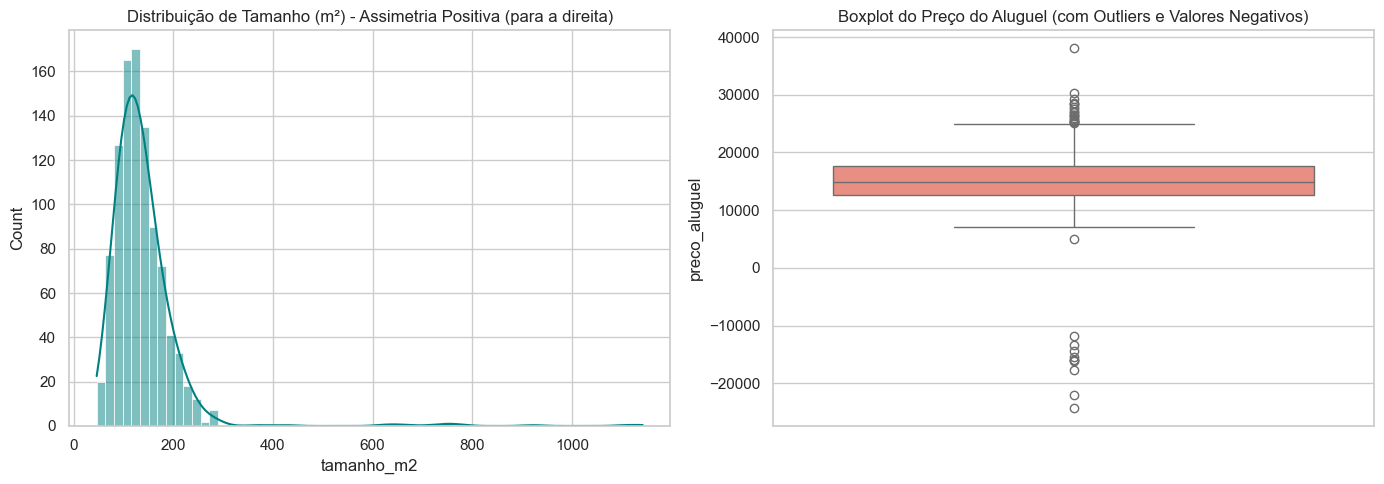

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma com curva KDE pata Tamanho
sns.histplot(df_raw["tamanho_m2"].dropna(), kde=True, ax=axes[0], color="teal")
axes[0].set_title("Distribuição de Tamanho (m²) - Assimetria Positiva (para a direita)")

# Boxplot para identificar Outliers em Preço
sns.boxplot(y=df_raw["preco_aluguel"], ax=axes[1], color="salmon")
axes[1].set_title("Boxplot do Preço do Aluguel (com Outliers e Valores Negativos)")

plt.tight_layout()
plt.show()

# <font color='blue'> Limpeza e Tratamento dos Dados

<font color='red'> Remover **linha duplicadas**:

In [56]:
df_clean = df_raw.drop_duplicates().copy()

In [57]:
# ! verificando a remoção das linhas duplicadas
df_clean.duplicated().sum()

np.int64(0)

<font color='red'> Remover **valores negativos** impossívels (preco_aluguel e tamanho_m2)

In [58]:
df_clean = df_clean[(df_clean["preco_aluguel"] > 0) & (df_clean["tamanho_m2"] > 0)]

In [59]:
# ! verificando a remoção dos dados negativos
df_clean.describe()

,Unnamed: 0,tamanho_m2,idade_imovel,num_banheiros,proximidade_metro,preco_aluguel
count,972.000000,972.000000,972.000000,972.000000,875.000000,972.000000
mean,518.513374,139.537607,19.468107,2.972222,0.772122,15473.950631
std,299.779230,83.814804,11.571477,1.347175,0.778171,3843.793311
min,0.000000,46.431281,0.000000,1.000000,0.000193,4945.643377
25%,258.750000,100.744021,10.000000,2.000000,0.220580,12763.720903
50%,518.500000,125.946636,19.000000,3.000000,0.518707,14993.248441
75%,777.250000,157.523592,29.000000,4.000000,1.103177,17677.611738
max,1034.000000,1142.190464,39.000000,7.000000,6.020163,30401.487593


<font color='red'> Tratamento de **Outliers**: </font> <br>
*obs:* usamores o critério IQR

In [60]:
def limpar_outliers_iqr (df, coluna):
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1

    limite_superior = Q3 + 1.5 * IQR
    limite_inferior = Q1 - 1.5 * IQR

    return df[(df[coluna] <= limite_superior) & (df[coluna] >= limite_inferior)]

In [61]:
df_clean = limpar_outliers_iqr(df_clean, "tamanho_m2")
df_clean = limpar_outliers_iqr(df_clean, "preco_aluguel")

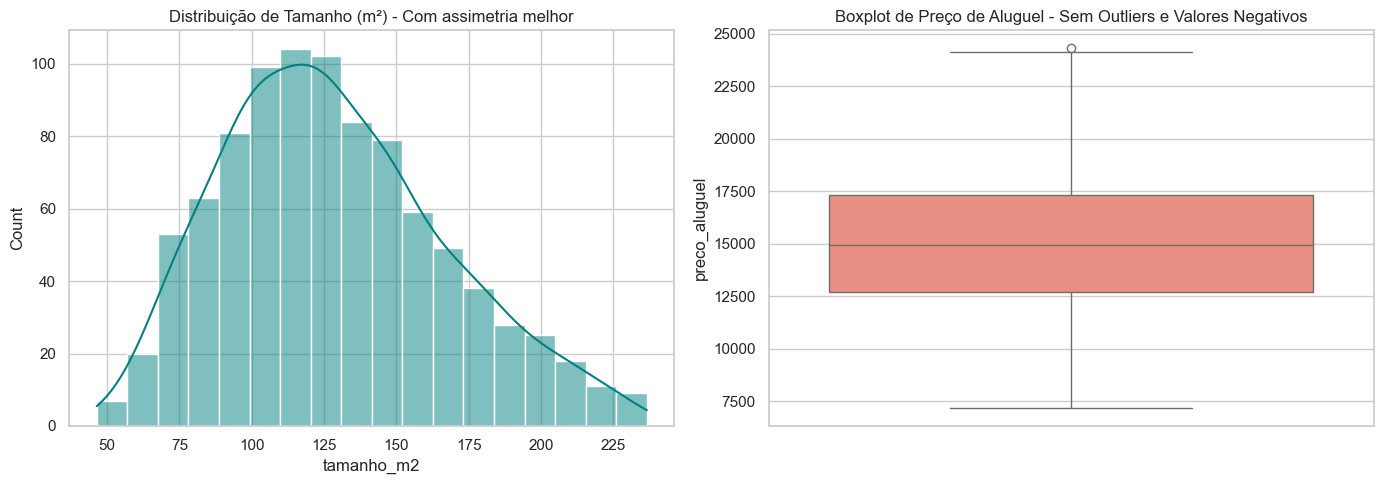

In [62]:
# !verificando os Outliers removidos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_clean["tamanho_m2"], kde=True, ax=axes[0], color="teal")
axes[0].set_title("Distribuição de Tamanho (m²) - Com assimetria melhor")
sns.boxplot(y=df_clean["preco_aluguel"], ax=axes[1], color="salmon")
axes[1].set_title("Boxplot de Preço de Aluguel - Sem Outliers e Valores Negativos")

plt.tight_layout()
plt.show()

<font color='red'> Tratamento de **valores nulos:** </font> <br>
*obs:* usaremos a Mediana

In [63]:
df_clean.isnull().sum()

Unnamed: 0            0
tamanho_m2            0
idade_imovel          0
num_banheiros         0
proximidade_metro    95
preco_aluguel         0
dtype: int64

In [64]:
for col in ["tamanho_m2", "proximidade_metro"]:
    if df_clean[col].isnull().sum() > 0:
        mediana_val = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(mediana_val)

In [65]:
# !verificando se so valores nulos foram removidos
df_clean.isnull().sum()

Unnamed: 0           0
tamanho_m2           0
idade_imovel         0
num_banheiros        0
proximidade_metro    0
preco_aluguel        0
dtype: int64

<font color='red'> Estatística Descritiva **Final**:

In [66]:
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,929.0,517.086114,300.865524,0.000000,258.000000,516.000000,776.000000,1034.000000
tamanho_m2,929.0,128.267099,38.386433,46.431281,100.115341,124.008044,152.524665,236.554028
idade_imovel,929.0,19.330463,11.578608,0.000000,9.000000,19.000000,29.000000,39.000000
num_banheiros,929.0,2.942949,1.327745,1.000000,2.000000,3.000000,4.000000,7.000000
proximidade_metro,929.0,0.742834,0.725207,0.000193,0.249631,0.518763,1.001293,6.020163
preco_aluguel,929.0,15144.230355,3388.870684,7168.248533,12712.730785,14936.585510,17317.168586,24299.836934


# <font color='blue'> Exportando o Dataset limpo

Exportando o Dataset limpo e pronto para confecção do algoritmo

Removendo a coluna 'Unnamed: 0':

In [67]:
df_clean.drop(columns=["Unnamed: 0"])

,tamanho_m2,idade_imovel,num_banheiros,proximidade_metro,preco_aluguel
0,146.480693,39,4,0.400952,15216.435887
1,117.486173,20,3,1.508170,10888.829048
2,113.577868,37,4,0.543368,13961.798360
3,113.578527,19,3,0.510779,14082.040617
4,209.539682,28,3,0.539166,22377.220420
...,...,...,...,...,...
1030,102.986728,10,4,1.555650,12969.412548
1031,155.881959,8,4,1.221349,18014.283346
1032,126.691918,19,3,0.112983,16201.392993
1033,136.236934,33,3,0.704844,15751.860236


In [68]:
df_clean = df_clean.drop(columns=["Unnamed: 0"])
df_clean.head()

,tamanho_m2,idade_imovel,num_banheiros,proximidade_metro,preco_aluguel
0,146.480693,39,4,0.400952,15216.435887
1,117.486173,20,3,1.508170,10888.829048
2,113.577868,37,4,0.543368,13961.798360
3,113.578527,19,3,0.510779,14082.040617
4,209.539682,28,3,0.539166,22377.220420


In [93]:
# Exportando os dados
df_clean.to_csv("../dataset/df_clean.csv", index=False)

In [92]:
df_clean

,tamanho_m2,idade_imovel,num_banheiros,proximidade_metro,preco_aluguel
0,146.480693,39,4,0.400952,15216.435887
1,117.486173,20,3,1.508170,10888.829048
2,113.577868,37,4,0.543368,13961.798360
3,113.578527,19,3,0.510779,14082.040617
4,209.539682,28,3,0.539166,22377.220420
...,...,...,...,...,...
1030,102.986728,10,4,1.555650,12969.412548
1031,155.881959,8,4,1.221349,18014.283346
1032,126.691918,19,3,0.112983,16201.392993
1033,136.236934,33,3,0.704844,15751.860236


# <font color='blue'> Análise Inferencial e Diagnóstico de Multicolinearidade

Vamos analisar a correlação entre as variáveis e o <font color='lightblue'> **Fator de Inflação da Variância (VIF)** </font> para garantir que não há multicolinearidade severa violando as **premissas de Gauss-Markov**. <br>
Isso garante que tenhamos **menor variância** possível entre TODOS os 'estimatores lineares' que **NÃO** possuem Viés (ou seja, acertam o valor real na média)

Isso garante que tenhamos **menor variância** possível entre TODOS os 'estimatores lineares' que **NÃO** possuem Viés (ou seja, acertam o valor real na média)

Matriz de correlação **de Pearson**

In [70]:
corr_matrix = df_clean[["preco_aluguel", "tamanho_m2", "idade_imovel", "num_banheiros", "proximidade_metro"]].corr(method="pearson")
corr_matrix

,preco_aluguel,tamanho_m2,idade_imovel,num_banheiros,proximidade_metro
preco_aluguel,1.000000,0.906550,-0.092627,0.104672,-0.181241
tamanho_m2,0.906550,1.000000,0.063443,-0.024765,0.072675
idade_imovel,-0.092627,0.063443,1.000000,-0.025338,0.036044
num_banheiros,0.104672,-0.024765,-0.025338,1.000000,0.039644
proximidade_metro,-0.181241,0.072675,0.036044,0.039644,1.000000


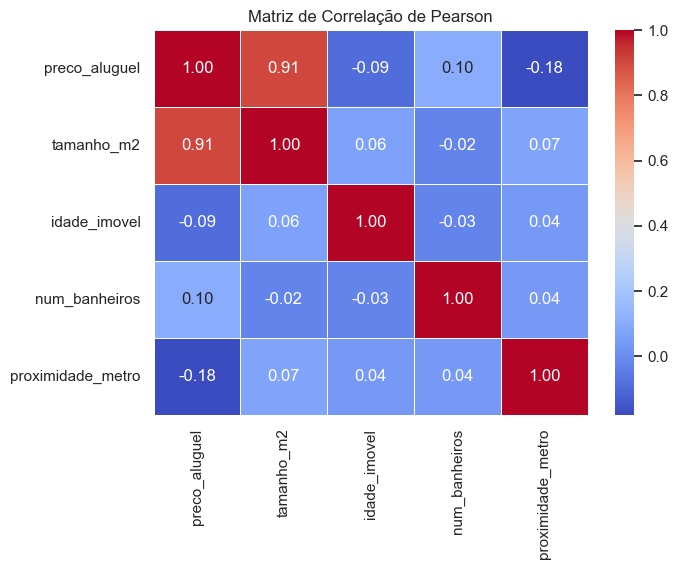

In [71]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Matriz de Correlação de Pearson")
plt.show()

<font color='red'> Diagnóstico de **VIF** (Multicolinearidade)

In [72]:
# Bibliotecas
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [73]:
# Variáveis analisadas
X_vif = sm.add_constant(df_clean[["tamanho_m2", "idade_imovel", "num_banheiros", "proximidade_metro"]])
print(X_vif)

      const  tamanho_m2  idade_imovel  num_banheiros  proximidade_metro
0       1.0  146.480693            39              4           0.400952
1       1.0  117.486173            20              3           1.508170
2       1.0  113.577868            37              4           0.543368
3       1.0  113.578527            19              3           0.510779
4       1.0  209.539682            28              3           0.539166
...     ...         ...           ...            ...                ...
1030    1.0  102.986728            10              4           1.555650
1031    1.0  155.881959             8              4           1.221349
1032    1.0  126.691918            19              3           0.112983
1033    1.0  136.236934            33              3           0.704844
1034    1.0   68.538383             2              2           0.243347

[929 rows x 5 columns]


In [74]:
# Shape: Linhas x Colunas
X_vif.shape

(929, 5)

In [75]:
# Valores de cada linha (em formato de Matriz)
X_vif.values

array([[1.00000000e+00, 1.46480693e+02, 3.90000000e+01, 4.00000000e+00,
        4.00951752e-01],
       [1.00000000e+00, 1.17486173e+02, 2.00000000e+01, 3.00000000e+00,
        1.50816962e+00],
       [1.00000000e+00, 1.13577868e+02, 3.70000000e+01, 4.00000000e+00,
        5.43368139e-01],
       ...,
       [1.00000000e+00, 1.26691918e+02, 1.90000000e+01, 3.00000000e+00,
        1.12983187e-01],
       [1.00000000e+00, 1.36236934e+02, 3.30000000e+01, 3.00000000e+00,
        7.04843772e-01],
       [1.00000000e+00, 6.85383826e+01, 2.00000000e+00, 2.00000000e+00,
        2.43346587e-01]], shape=(929, 5))

In [76]:
vif_df = pd.DataFrame()
vif_df["Variável"] = X_vif.columns
vif_df.head()

,Variável
0,const
1,tamanho_m2
2,idade_imovel
3,num_banheiros
4,proximidade_metro


Adicionando o VIF: <br>
VIF levemante acima de 1: indica uma correlação moderada (geralmente aceitável e não prejudicial ao modelo)

In [77]:
vif_df["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
vif_df.head()

,Variável,VIF
0,const,20.182018
1,tamanho_m2,1.009759
2,idade_imovel,1.005681
3,num_banheiros,1.002981
4,proximidade_metro,1.008121


# <font color='blue'> Modelo OLS e Sumário Estatístico

Vamos utilizar o Modelo OLS para estimar os melhores **coeficientes angulares** e **intercepto**

In [78]:
# Bibliotecas
import statsmodels.api as sm

In [79]:
# Definindo Variável Dependente (Y) e Independentes (X com constante)
Y = df_clean["preco_aluguel"]
X = sm.add_constant(df_clean[["tamanho_m2", "idade_imovel", "num_banheiros", "proximidade_metro"]])

# Ajustando o modelo OLS
modelo_ols = sm.OLS(Y, X).fit()

print(modelo_ols.summary())

                            OLS Regression Results                            
Dep. Variable:          preco_aluguel   R-squared:                       0.922
Model:                            OLS   Adj. R-squared:                  0.921
Method:                 Least Squares   F-statistic:                     2714.
Date:                Wed, 14 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:48:02   Log-Likelihood:                -7686.5
No. Observations:                 929   AIC:                         1.538e+04
Df Residuals:                     924   BIC:                         1.541e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const              5183.6394    140.20

# <font color='blue'> Análise de Resíduos (Validação de Premisas)

Para que uma Regressão Linear seja válida, os resíduos do modelo (^y - y) devem serguir algumas premissas:
* **Média zero:** o erro esperado é nulo.
* **Homoscedasticidade:** deve haver uma Variância constante dos resíduos ao longo dos valores ajustados.
* **Normalidade:** os resíduos devem seguir uma Distribuição Normal (verificada via Teste de Shapiro-Wilk)

In [80]:
residuos = modelo_ols.resid
residuos

0      -1391.123309
1      -2463.162557
2        160.003651
3       -151.027283
4        608.198878
           ...     
1030     120.672529
1031     318.867770
1032     419.706195
1033     443.370364
1034    -120.318655
Length: 929, dtype: float64

In [81]:
valores_ajustados = modelo_ols.fittedvalues
valores_ajustados

0       16607.559197
1       13351.991605
2       13801.794709
3       14233.067900
4       21769.021542
            ...     
1030    12848.740019
1031    17695.415576
1032    15781.686797
1033    15308.489873
1034    11172.060845
Length: 929, dtype: float64

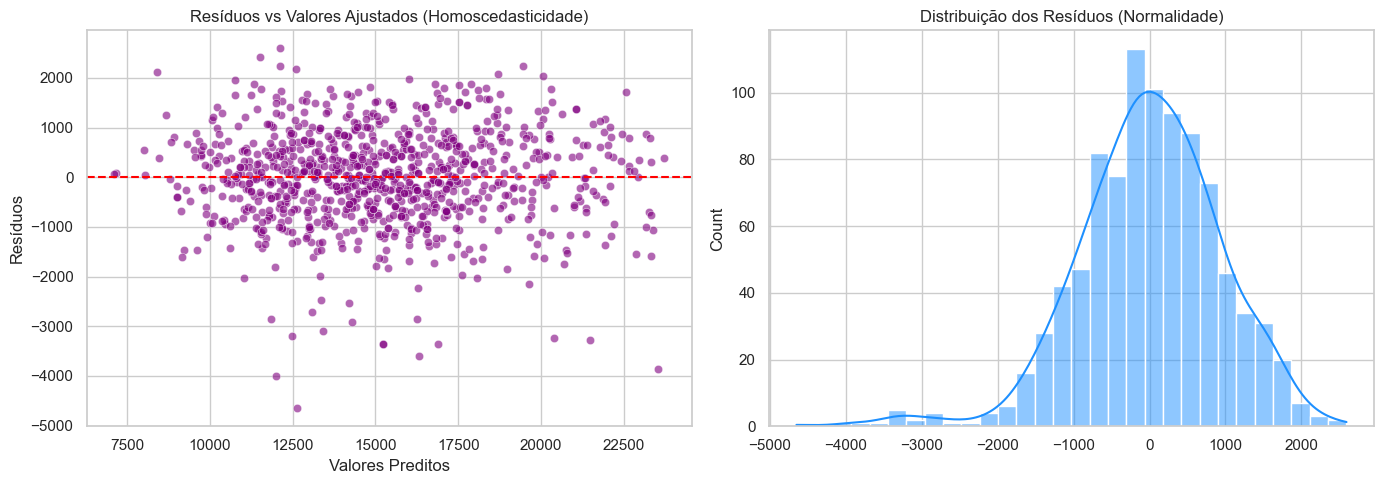

In [82]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de Homoscedasticidade (Resíduos vs Valores Ajustados)
sns.scatterplot(x=valores_ajustados, y=residuos, ax=axes[0], alpha=0.6, color="purple")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Resíduos vs Valores Ajustados (Homoscedasticidade)")
axes[0].set_xlabel("Valores Preditos")
axes[0].set_ylabel("Resíduos")

# Histograma dos Resíduos com Curva Normal
sns.histplot(residuos, kde=True, ax=axes[1], color="dodgerblue")
axes[1].set_title("Distribuição dos Resíduos (Normalidade)")

plt.tight_layout()
plt.show()

<font color='red'> Teste Shapiro-Wilk: teste estatístico de normalidade </font> <Br>
Interpretação dos resultados:
* Estatística W = 0.97: forte indicação **visual** de uma Distribuição Normal. <Br> *obs:* apenas visual.
* p-value = 2.2897...e-11: muito abaixo de 0.05, ou seja, rejeitamos H0. <Br> O p-value mostra que não há hipóteses de aleatoriedade e os dados não são uma Distribuição Normal.

In [83]:
# Bibliotecas
from scipy.stats import shapiro

In [84]:
shapiro_test = shapiro(residuos)
shapiro_test

ShapiroResult(statistic=np.float64(0.975596471953606), pvalue=np.float64(2.2897436879537885e-11))

In [85]:
print("Estatística W: ", shapiro_test.statistic)
print("p-value: ", shapiro_test.pvalue)

Estatística W:  0.975596471953606
p-value:  2.2897436879537885e-11


<font color='red'> Q-Q Plot:

O gráfico Q-Q Plot permite analisar profundamente a distribuição dos resíduos. <Br>
No mundo real, o teste de Shapiro-Wilk **quase sempre** rejeita H0 (dados não são uma Distribuição Normal) e o gráfico Q-Q Plot permite analisar essa distribuição corretamente
<Br><Br>
Resultado: curva levemente em formato de S (acentuaação maior na porção inferior) mas com **região central fortemente alinhada** <Br>
Seguindo o Teorema do Limite Central define que em muitos dados teremos uma Distirbuição Normal.

In [86]:
# Bibliotecas
import matplotlib.pyplot as plt
import scipy.stats as stats

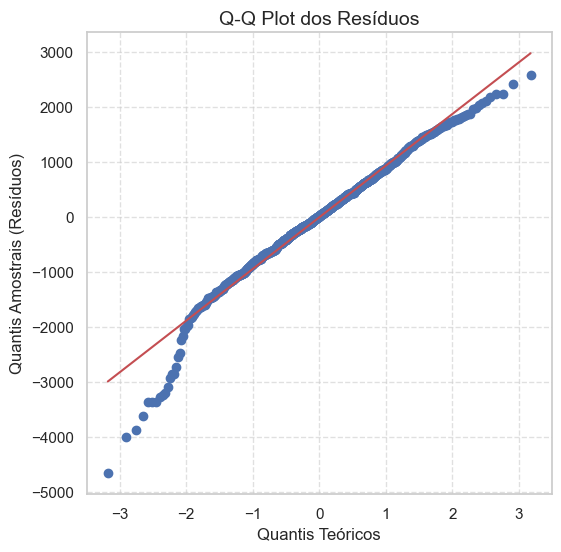

In [87]:
fig, ax = plt.subplots(figsize=(6, 6))

stats.probplot(residuos, dist="norm", plot=ax)
ax.set_title("Q-Q Plot dos Resíduos", fontsize=14)
ax.set_xlabel("Quantis Teóricos", fontsize=12)
ax.set_ylabel("Quantis Amostrais (Resíduos)", fontsize=12)

plt.grid(True, linestyle="--", alpha=0.6)
plt.show()